# Tox21 · Member 4: a Graph Convolutional Network on molecular graphs

**Phase 2 of the project.** Phase 1 turned each molecule into a *fixed* vector (Morgan fingerprint, RDKit descriptors) and trained Logistic Regression, Random Forest and XGBoost on it. This notebook keeps the molecule as a **graph** — atoms are nodes, bonds are edges — and lets a Graph Convolutional Network (GCN) learn its own representation while it learns the task.

**Self-contained Google Colab notebook.** It needs only Member 1's frozen split files: `tox21_train.csv`, `tox21_val.csv`, `tox21_test.csv` (and optionally `tox21_clean.csv` for a cross-check, plus `all_models_metrics.csv` from notebook 03 for the final comparison).

**How to run:** *Runtime → Run all*. When step 1 asks, upload the CSV files. The whole notebook takes about 10 minutes on a free Colab CPU; no GPU is needed.

Project rules this notebook follows, exactly as notebooks 02 and 03 do:
* Member 1's split is only **read and verified**, never changed. Scaffolds must not overlap between train, validation and test.
* **Missing labels stay missing.** They are masked out of the loss and excluded from every metric. A label that was never measured is not evidence of inactivity.
* Anything fitted — here the atom-feature vocabulary — is built from **training molecules only**.
* Hyperparameters and the number of epochs are chosen on **validation ROC-AUC** (PR-AUC breaks ties). The **test set is used once**, at the end, after every choice is frozen.
* Seed = 42. Every number shown is computed from the uploaded data.

**What this notebook can and cannot settle.** The GCN sees the structure and nothing else, so the fair comparison is against the Phase 1 models **on Morgan fingerprints**, which also see structure alone. One split, one seed and no confidence intervals: a small difference between models is not a result. The models predict **in-vitro Tox21 assay activity**, not human toxicity.

## 0. Install and import

In [1]:
import sys, subprocess

def ensure(package: str, import_name: str = None):
    """Import a package, installing it first if the environment does not have it (Colab needs rdkit)."""
    try:
        return __import__(import_name or package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
        return __import__(import_name or package)

rdkit = ensure("rdkit")
torch = ensure("torch")

import json, math, os, re, shutil, time, warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
from sklearn.metrics import average_precision_score, roc_auc_score

# index_reduce_ (used for max pooling) is a stable, documented operation that PyTorch still marks beta.
warnings.filterwarnings("ignore", message=".*index_reduce.*")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
print({"python": sys.version.split()[0], "torch": torch.__version__, "rdkit": rdkit.__version__,
       "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__})
print("device: CPU only (this model is small; a GPU changes nothing but the speed)")

{'python': '3.13.6', 'torch': '2.9.0', 'rdkit': '2026.09.1', 'scikit-learn': '1.6.1', 'numpy': '2.2.5', 'pandas': '2.2.3'}
device: CPU only (this model is small; a GPU changes nothing but the speed)


### Settings

The grid is deliberately small and ordered **simplest first**, like notebook 03: a few settings, each one tuned on validation. `FIXED` holds the settings that are not searched, so every number in the notebook can be traced to one of these two cells.

One difference from Phase 1 worth stating plainly. Notebooks 02 and 03 tune **one model per endpoint**, so each of their 108 classifiers has its own hyperparameters. A GCN is naturally **multi-task**: one network with 12 outputs, sharing its representation across all endpoints, so there is one configuration for all 12. That is a difference in the method, not a shortcut, and it is reported with the results.

In [2]:
SEED = 42
TASKS = ["NR-AR", "NR-AR-LBD", "NR-AhR", "NR-Aromatase", "NR-ER", "NR-ER-LBD",
         "NR-PPAR-gamma", "SR-ARE", "SR-ATAD5", "SR-HSE", "SR-MMP", "SR-p53"]
SPLITS = ["train", "val", "test"]
SELECTION_METRIC = "roc_auc"        # team decision: choose on validation ROC-AUC, PR-AUC breaks ties
FEATURE_SET = "graph"               # the GCN's "features" are the molecular graph itself
MODEL_NAME = "gnn"

# Searched on validation (16 combinations, simplest value first)
GRID = {
    "hidden": [64, 128],            # width of each graph-convolution layer
    "layers": [2, 3],               # message-passing steps: how far information travels
    "lr": [5e-4, 1e-3],             # Adam learning rate
    "pos_weight": [False, True],    # weight actives in the loss (the GCN's class-imbalance option)
}
# Not searched. Kept fixed so the grid stays small and honest.
FIXED = {"dropout": 0.2, "weight_decay": 1e-5, "batch_size": 128}
MAX_EPOCHS = 150                    # upper bound; early stopping almost always ends a run sooner
PATIENCE = 25                       # stop when validation ROC-AUC has not improved for this many epochs
SEED_CHECK = [42, 43, 44]           # seed-stability check, validation only

RESULTS_DIR = Path("results/gnn")
MODEL_DIR = Path("models/gnn")
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f"Grid: {np.prod([len(v) for v in GRID.values()])} configurations | fixed: {FIXED}")

Grid: 16 configurations | fixed: {'dropout': 0.2, 'weight_decay': 1e-05, 'batch_size': 128}


## 1. Get Member 1's data

In Colab an upload button appears if the files are not already in `/content/tox21_data`.
*Alternative:* mount Google Drive (`from google.colab import drive; drive.mount('/content/drive')`) and set `DATA_DIR` to the Drive folder that holds the CSVs.

Optional extras, if you have them: `tox21_clean.csv` (cross-check of the split) and `all_models_metrics.csv` from notebook 03 (so section 8 can compare the GCN with Phase 1).

In [3]:
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATA_DIR = Path("/content/tox21_data") if IN_COLAB else Path(os.environ.get("TOX21_DATA_DIR", "."))
REQUIRED_FILES = [f"tox21_{s}.csv" for s in SPLITS]

def missing_files():
    return [f for f in REQUIRED_FILES if not (DATA_DIR / f).is_file()]

if missing_files() and IN_COLAB:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Please upload:", ", ".join(REQUIRED_FILES), "(optionally tox21_clean.csv and all_models_metrics.csv)")
    for name, content in colab_files.upload().items():
        clean_name = re.sub(r" \(\d+\)(?=\.csv$)", "", Path(name).name)   # "tox21_train (1).csv" -> "tox21_train.csv"
        (DATA_DIR / clean_name).write_bytes(content)

if missing_files():
    raise FileNotFoundError(f"Missing {missing_files()} in the data folder {DATA_DIR}")
print("Data folder:", DATA_DIR, "|", sorted(p.name for p in DATA_DIR.glob("*.csv")))

Data folder: . | ['all_models_metrics.csv', 'tox21_clean.csv', 'tox21_test.csv', 'tox21_train.csv', 'tox21_val.csv']


## 2. Load and verify the frozen split

The same checks as notebooks 02 and 03, using the same code. If any check fails the notebook stops rather than training on a changed split.

In [4]:
class SplitIntegrityError(ValueError):
    pass

def read_tox21_csv(path: Path) -> pd.DataFrame:
    """Read one split file. Labels stay float so missing values remain NaN (never 0)."""
    df = pd.read_csv(path, dtype={"mol_id": str, "smiles": str, "scaffold": str, "split": str})
    missing = [c for c in ["mol_id", "smiles", "scaffold", "split", *TASKS] if c not in df.columns]
    if missing:
        raise SplitIntegrityError(f"{path.name} is missing columns {missing}")
    df["scaffold"] = df["scaffold"].fillna("")        # acyclic molecules have an empty scaffold
    df[TASKS] = df[TASKS].astype(float)
    return df

def verify_frozen_splits(splits: Dict[str, pd.DataFrame], clean_df: Optional[pd.DataFrame] = None) -> None:
    for name, df in splits.items():
        if (df["split"] != name).any() or df["mol_id"].duplicated().any():
            raise SplitIntegrityError(f"{name}: wrong split labels or duplicate mol_ids")
        values = df[TASKS].to_numpy()
        if not np.isin(values[~np.isnan(values)], (0.0, 1.0)).all():
            raise SplitIntegrityError(f"{name} has labels other than 0, 1 or NaN")
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        if set(splits[a]["mol_id"]) & set(splits[b]["mol_id"]):
            raise SplitIntegrityError(f"mol_ids shared by {a} and {b}")
        if set(splits[a]["scaffold"]) & set(splits[b]["scaffold"]):
            raise SplitIntegrityError(f"scaffolds shared by {a} and {b}")
    if clean_df is not None:
        for name in SPLITS:
            if set(clean_df.loc[clean_df["split"] == name, "mol_id"]) != set(splits[name]["mol_id"]):
                raise SplitIntegrityError(f"tox21_{name}.csv does not match tox21_clean.csv")

def label_counts(df: pd.DataFrame) -> pd.DataFrame:
    y = df[TASKS]
    return pd.DataFrame({"n_observed": y.notna().sum(), "n_positive": (y == 1).sum(),
                         "n_negative": (y == 0).sum(), "n_missing": y.isna().sum()}).rename_axis("endpoint")

splits = {s: read_tox21_csv(DATA_DIR / f"tox21_{s}.csv") for s in SPLITS}
clean_path = DATA_DIR / "tox21_clean.csv"
verify_frozen_splits(splits, read_tox21_csv(clean_path) if clean_path.is_file() else None)
labels = {s: splits[s][TASKS].to_numpy(dtype=float) for s in SPLITS}   # row i <-> splits[s].mol_id[i]
counts = pd.concat({s: label_counts(df) for s, df in splits.items()}, axis=1)
print("Split verified:", {s: len(df) for s, df in splits.items()}, "| no shared scaffolds or mol_ids"
      + (" | cross-checked with tox21_clean.csv" if clean_path.is_file() else ""))
counts

Split verified: {'train': 6166, 'val': 771, 'test': 771} | no shared scaffolds or mol_ids | cross-checked with tox21_clean.csv


train                                        val                                       test                                
              n_observed n_positive n_negative n_missing n_observed n_positive n_negative n_missing n_observed n_positive n_negative n_missing
endpoint                                                                                                                                      
NR-AR               5740        248       5492       426        710         42        668        61        691         14        677        80
NR-AR-LBD           5430        196       5234       736        623         27        596       148        598         12        586       173
NR-AhR              5235        579       4656       931        626         74        552       145        582        110        472       189
NR-Aromatase        4714        197       4517      1452        512         36        476       259        490         53        437       281
NR-ER               5028        643       4385      1138        536         65        471       235        537         72        465       234
NR-ER-LBD           5560        296       5264       606        659         23        636       112        631         24        607       140
NR-PPAR-gamma       5234        129       5105       932        560         24        536       211        559         32        527       212
SR-ARE              4790        685       4105      1376        449        110        339       322        497        120        377       274
SR-ATAD5            5657        195       5462       509        659         33        626       112        645         33        612       126
SR-HSE              5230        272       4958       936        537         37        500       234        605         55        550       166
SR-MMP              4722        698       4024      1444        540        120        420       231        465         89        376       306
SR-p53              5426        275       5151       740        628         69        559       143        618         75        543       153

## 3. Shared metrics

The **same** metric function as notebooks 02 and 03, so the GCN's numbers are directly comparable: ROC-AUC and PR-AUC (average precision) per endpoint, computed only on rows with an observed label, and NaN when only one class is present.

In [5]:
def compute_binary_metrics(y_true, y_prob) -> dict:
    y_true, y_prob = np.asarray(y_true, float), np.asarray(y_prob, float)
    observed = ~np.isnan(y_true)
    y, p = y_true[observed], y_prob[observed]
    n_pos, n_neg = int((y == 1).sum()), int((y == 0).sum())
    out = {"n_observed": int(observed.sum()), "n_positive": n_pos, "n_negative": n_neg,
           "roc_auc": np.nan, "pr_auc": np.nan}
    if n_pos and n_neg and not np.isnan(p).any():
        out["roc_auc"] = float(roc_auc_score(y, p))
        out["pr_auc"] = float(average_precision_score(y, p))
    return out

def evaluate_endpoints(y_true: np.ndarray, y_prob: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame([{"endpoint": t, **compute_binary_metrics(y_true[:, j], y_prob[:, j])}
                         for j, t in enumerate(TASKS)])

def mean_scores(frame: pd.DataFrame) -> tuple:
    """(mean ROC-AUC, mean PR-AUC) over the endpoints where the metric is defined."""
    return float(frame["roc_auc"].mean()), float(frame["pr_auc"].mean())

## 4. From SMILES to a molecular graph

A fingerprint throws the molecule away and keeps a bit vector. A graph keeps the molecule: every heavy atom is a node carrying a feature vector, and every bond is an edge in both directions.

**Atom features.** Eight blocks, all read straight from RDKit, all one-hot except the last two flags:

| Block | Values | Why it matters |
| --- | --- | --- |
| element | vocabulary built from the **training** molecules, plus an `other` bucket | carbon and chlorine behave differently |
| total degree | 0–5, plus `other` | how many neighbours the atom has |
| formal charge | −2…+2, plus `other` | charged groups bind differently |
| attached hydrogens | 0–4, plus `other` | distinguishes CH₃ from CH₂ from CH |
| multiple bonds | 0, 1, 2, plus `other` | double and triple bonds on this atom |
| total valence | 1–6, plus `other` | bond orders plus hydrogens |
| aromatic | flag | aromatic rings are a recurring toxicophore motif |
| in a ring | flag | ring membership changes reactivity |

Every block has an `other` bucket, so a value never seen in training (an exotic metal in the test set, say) still produces a valid vector instead of crashing. The element vocabulary is built from **training molecules only** — the same rule that makes notebook 02 fit its imputer and scaler on training rows only.

**Why not hybridisation?** The obvious eighth block would be RDKit's `GetHybridization()` (SP, SP2, SP3 …), and an earlier version of this notebook used it. It was replaced because the website runs this model in the visitor's browser, where RDKit is compiled to WebAssembly and exposes the molecule as JSON: atomic numbers, charges, implicit hydrogens, bond orders, aromatic flags and rings — but **not** hybridisation, which RDKit derives internally from its conjugation perception. Every other block was checked against Python RDKit on all 140,937 atoms of the dataset and matches exactly; hybridisation cannot be reproduced without reimplementing RDKit's internals, and an approximation would be silently wrong on some molecule a visitor types in.

The multiple-bond count and total valence carry much of the same information and are read straight from the bond orders. The swap costs 0.0015 mean validation ROC-AUC (0.7615 → 0.7600 for the chosen configuration), which is smaller than the spread between random seeds, so the model reported here is the one that can also be proven correct in the browser.

Bond *types* are deliberately not used **as edge weights**: a plain GCN averages over neighbours without weighting by bond order. That is the Kipf–Welling model this phase set out to implement, and it is also a limitation (see the viva notes at the end). Bond orders still reach the model through the two atom-feature blocks above.

In [6]:
DEGREES, CHARGES, NUM_HS = [0, 1, 2, 3, 4, 5], [-2, -1, 0, 1, 2], [0, 1, 2, 3, 4]
PI_BONDS, VALENCES = [0, 1, 2], [1, 2, 3, 4, 5, 6]

def one_hot(value, options: Sequence) -> List[float]:
    """One-hot with a trailing 'other' bucket, so an unseen value is representable."""
    vector = [0.0] * (len(options) + 1)
    vector[options.index(value) if value in options else len(options)] = 1.0
    return vector

def parse_smiles(smiles: str):
    RDLogger.DisableLog("rdApp.*")
    mol = Chem.MolFromSmiles(smiles)
    RDLogger.EnableLog("rdApp.*")
    if mol is None or mol.GetNumAtoms() == 0:
        raise ValueError(f"RDKit could not read the SMILES {smiles!r}")
    return mol

def element_vocabulary(smiles_list: Sequence[str]) -> List[str]:
    """Elements present in the TRAINING molecules; anything else becomes 'other'."""
    seen = {atom.GetSymbol() for smiles in smiles_list for atom in parse_smiles(smiles).GetAtoms()}
    return sorted(seen)

def pi_bond_count(atom) -> int:
    """Double and triple bonds on this atom. Aromatic bonds count through the aromatic flag instead."""
    return sum(1 for bond in atom.GetBonds() if bond.GetBondTypeAsDouble() >= 2)

def atom_features(atom, elements: List[str]) -> List[float]:
    """Every block here is reproducible from RDKit's JSON export, so the browser computes
    bit-identical features (checked in the website's parity test)."""
    return (one_hot(atom.GetSymbol(), elements)
            + one_hot(atom.GetTotalDegree(), DEGREES)
            + one_hot(atom.GetFormalCharge(), CHARGES)
            + one_hot(atom.GetTotalNumHs(), NUM_HS)
            + one_hot(pi_bond_count(atom), PI_BONDS)
            + one_hot(int(atom.GetTotalValence()), VALENCES)
            + [float(atom.GetIsAromatic()), float(atom.IsInRing())])

def feature_names(elements: List[str]) -> List[str]:
    blocks = [("element", elements), ("degree", DEGREES), ("charge", CHARGES),
              ("numH", NUM_HS), ("pi_bonds", PI_BONDS), ("valence", VALENCES)]
    names = [f"{block}_{value}" for block, options in blocks for value in list(options) + ["other"]]
    return names + ["is_aromatic", "in_ring"]

@dataclass
class Graph:
    """One molecule. x[i] is atom i's feature vector; edge_index holds both directions of every bond."""
    x: np.ndarray
    edge_index: np.ndarray

    @property
    def n_atoms(self) -> int:
        return self.x.shape[0]

def to_graph(smiles: str, elements: List[str]) -> Graph:
    mol = parse_smiles(smiles)
    x = np.array([atom_features(a, elements) for a in mol.GetAtoms()], dtype=np.float32)
    source, target = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        source += [i, j]                      # undirected: store both directions
        target += [j, i]
    return Graph(x, np.array([source, target], dtype=np.int64).reshape(2, -1))

In [7]:
start = time.time()
ELEMENTS = element_vocabulary(splits["train"]["smiles"])
FEATURE_NAMES = feature_names(ELEMENTS)
graphs = {s: [to_graph(smiles, ELEMENTS) for smiles in splits[s]["smiles"]] for s in SPLITS}
N_FEATURES = graphs["train"][0].x.shape[1]
assert len(FEATURE_NAMES) == N_FEATURES
unseen = sorted({a.GetSymbol() for s in ["val", "test"] for smi in splits[s]["smiles"]
                 for a in parse_smiles(smi).GetAtoms()} - set(ELEMENTS))

print(f"Graphs built in {time.time() - start:.1f}s | atom feature dimension {N_FEATURES}")
print(f"Element vocabulary from training molecules ({len(ELEMENTS)}): {' '.join(ELEMENTS)}")
print(f"Elements seen only in validation/test, mapped to 'other': {unseen or 'none'}")
pd.DataFrame({s: {"molecules": len(graphs[s]),
                  "atoms (nodes)": sum(g.n_atoms for g in graphs[s]),
                  "bonds x2 (edges)": sum(g.edge_index.shape[1] for g in graphs[s]),
                  "atoms per molecule (median)": float(np.median([g.n_atoms for g in graphs[s]]))}
              for s in SPLITS})

Graphs built in 1.7s | atom feature dimension 77
Element vocabulary from training molecules (44): As Au B Ba Be Bi Br C Ca Cd Cl Co Cr Cu Dy F Fe Ge H Hg I In Mn Mo N Na Nd Ni O P Pb Pd Pt S Sb Se Si Sn Ti Tl V Yb Zn Zr
Elements seen only in validation/test, mapped to 'other': none


,train,val,test
molecules,6166.0,771.0,771.0
atoms (nodes),100564.0,22636.0,17737.0
bonds x2 (edges),205666.0,48862.0,38828.0
atoms per molecule (median),14.0,27.0,22.0


### One molecule, as the network sees it

TOX3021 CCOc1ccc2nc(S(N)(=O)=O)sc2c1 -> 16 nodes, 34 directed edges
measured active in: {'NR-AhR': np.float64(1.0), 'SR-ARE': np.float64(1.0)}


,atom,element_C,element_O,degree_2,degree_3,degree_4,charge_0,numH_0,numH_1,numH_2,numH_3,pi_bonds_0,valence_2,valence_4,is_aromatic,in_ring
0,C0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
1,C1,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2,O2,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
3,C3,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
4,C4,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
5,C5,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0


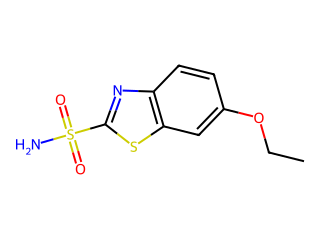

In [8]:
example = splits["train"].iloc[0]
mol = parse_smiles(example["smiles"])
graph = to_graph(example["smiles"], ELEMENTS)
print(example["mol_id"], example["smiles"], f"-> {graph.n_atoms} nodes, {graph.edge_index.shape[1]} directed edges")
active = {t: example[t] for t in TASKS if example[t] == 1}
print("measured active in:", active or "none of the 12 assays")

table = pd.DataFrame(graph.x, columns=FEATURE_NAMES)
table.insert(0, "atom", [f"{a.GetSymbol()}{a.GetIdx()}" for a in mol.GetAtoms()])
display(table.loc[:5, ["atom"] + [c for c in table.columns if table.loc[:5, c].any() and c != "atom"]])
Draw.MolToImage(mol, size=(320, 240))

### Batching many graphs into one sparse matrix

Molecules have different sizes, so they cannot be stacked into a rectangular tensor. The standard trick is a **block-diagonal batch**: stack all the atoms of all the molecules in the batch into one long node matrix, and build one sparse adjacency matrix whose blocks are the individual molecules. No edge crosses a block, so no information leaks between molecules, and the whole batch is one sparse matrix multiplication. A `batch` vector records which molecule each node belongs to, which is what the pooling step needs.

The adjacency used is the symmetrically normalised one from Kipf and Welling,

$$\hat{A} = \tilde{D}^{-1/2}\,(A + I)\,\tilde{D}^{-1/2},\qquad \tilde{D}_{ii} = \textstyle\sum_j (A+I)_{ij}$$

The added identity is the **self-loop**: without it an atom's own features would be lost at every step. The normalisation divides by the square root of both endpoints' degrees, so an atom in a crowded region does not simply shout louder than one in a sparse region.

In [9]:
def batch_graphs(batch_list: List[Graph]):
    """Block-diagonal batch: returns (node features, normalised sparse adjacency, batch index, n_graphs)."""
    xs, rows, cols, batch_index, offset = [], [], [], [], 0
    for i, g in enumerate(batch_list):
        xs.append(g.x)
        if g.edge_index.shape[1]:
            rows.append(g.edge_index[0] + offset)
            cols.append(g.edge_index[1] + offset)
        loop = np.arange(g.n_atoms) + offset          # self-loops: A + I
        rows.append(loop)
        cols.append(loop)
        batch_index.append(np.full(g.n_atoms, i, dtype=np.int64))
        offset += g.n_atoms
    x = torch.from_numpy(np.concatenate(xs))
    row = torch.from_numpy(np.concatenate(rows))
    col = torch.from_numpy(np.concatenate(cols))
    batch_index = torch.from_numpy(np.concatenate(batch_index))
    degree = torch.zeros(offset).index_add_(0, row, torch.ones(row.numel()))
    values = degree[row].pow(-0.5) * degree[col].pow(-0.5)          # D^-1/2 (A+I) D^-1/2
    adjacency = torch.sparse_coo_tensor(torch.stack([row, col]), values, (offset, offset)).coalesce()
    return x, adjacency, batch_index, len(batch_list)

# Two small molecules in one batch: the adjacency must be block-diagonal and symmetric, rows must sum sensibly.
demo = [to_graph("CCO", ELEMENTS), to_graph("c1ccccc1", ELEMENTS)]
x_demo, adj_demo, batch_demo, n_demo = batch_graphs(demo)
dense = adj_demo.to_dense()
assert torch.allclose(dense, dense.T, atol=1e-6)                        # symmetric
assert dense[:3, 3:].abs().max() == 0 and dense[3:, :3].abs().max() == 0  # no edge between the two molecules
print(f"batch of {n_demo} molecules -> {x_demo.shape[0]} nodes, adjacency {tuple(dense.shape)}, "
      f"{int(adj_demo._nnz())} non-zeros")
print("batch index:", batch_demo.tolist())
pd.DataFrame(dense[:3, :3].numpy(), index=["C0", "C1", "O2"], columns=["C0", "C1", "O2"]).round(3)

batch of 2 molecules -> 9 nodes, adjacency (9, 9), 25 non-zeros
batch index: [0, 0, 0, 1, 1, 1, 1, 1, 1]


,C0,C1,O2
C0,0.500,0.408,0.000
C1,0.408,0.333,0.408
O2,0.000,0.408,0.500


## 5. The network

**One graph-convolution layer.** Each layer transforms every atom's vector, then replaces it with the normalised average of itself and its neighbours:

$$H^{(l+1)} = \sigma\!\left(\hat{A}\,H^{(l)}\,W^{(l)} + b^{(l)}\right)$$

After *L* layers an atom's vector summarises everything within *L* bonds of it. This is the direct analogue of the Morgan fingerprint's radius — but where the fingerprint *hashes* each neighbourhood into a fixed bit, the GCN *learns* what to record about it. Batch normalisation and dropout are applied after each layer to keep training stable.

**Readout (pooling).** The 12 assay predictions are per molecule, not per atom, so the atom vectors must be reduced to one vector per molecule. We concatenate two views: the **mean** over atoms ("what is this molecule like on average") and the **maximum** over atoms ("does it contain *any* atom with this learned property anywhere"). The maximum matters for toxicity, where a single reactive group can decide the outcome. Both are permutation-invariant, so renumbering the atoms cannot change the prediction — checked in the self-test below.

**Masked loss.** The head produces 12 logits, one per assay. Binary cross-entropy is computed for all 12, then multiplied by a 0/1 mask that is 0 wherever the label was never measured, and averaged over the observed entries only:

$$\mathcal{L} = \frac{\sum_{i,t} m_{i,t}\,\mathrm{BCE}\!\left(z_{i,t},\,y_{i,t}\right)}{\sum_{i,t} m_{i,t}}$$

This is the one place where a careless implementation would quietly ruin the project: filling missing labels with 0 would teach the network that 17% of unmeasured pairs are inactive. The self-test checks that the gradient is unchanged when the values hidden behind the mask are altered.

**Class imbalance.** `pos_weight` multiplies the loss of every active molecule by (negatives / positives) for that endpoint, computed from the observed *training* labels. It is the GCN's counterpart to `class_weight` in Logistic Regression and `scale_pos_weight` in XGBoost, and like them it is a tuned option, not an assumption.

In [10]:
class GCN(nn.Module):
    """L graph-convolution layers, mean+max pooling, then a small MLP head with one logit per endpoint."""

    def __init__(self, in_dim: int, hidden: int, layers: int, n_tasks: int, dropout: float):
        super().__init__()
        dims = [in_dim] + [hidden] * layers
        self.convs = nn.ModuleList(nn.Linear(dims[i], dims[i + 1]) for i in range(layers))
        self.norms = nn.ModuleList(nn.BatchNorm1d(hidden) for _ in range(layers))
        self.head = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, n_tasks))
        self.dropout = dropout

    def forward(self, x, adjacency, batch_index, n_graphs):
        for conv, norm in zip(self.convs, self.norms):
            x = torch.sparse.mm(adjacency, conv(x))        # A_hat (H W): average over self and neighbours
            x = F.relu(norm(x))
            x = F.dropout(x, self.dropout, self.training)
        counts = torch.zeros(n_graphs, 1).index_add_(0, batch_index, torch.ones(batch_index.numel(), 1))
        mean = torch.zeros(n_graphs, x.shape[1]).index_add_(0, batch_index, x) / counts
        maximum = torch.zeros(n_graphs, x.shape[1]).index_reduce_(0, batch_index, x, "amax", include_self=False)
        return self.head(torch.cat([mean, maximum], dim=1))

def masked_bce(logits, y, mask, pos_weight=None):
    """Binary cross-entropy over observed labels only. nan_to_num only feeds the masked-out slots a finite number."""
    loss = F.binary_cross_entropy_with_logits(logits, torch.nan_to_num(y), pos_weight=pos_weight, reduction="none")
    return (loss * mask).sum() / mask.sum()

def endpoint_pos_weight(y_train: np.ndarray) -> torch.Tensor:
    """negatives / positives per endpoint, from observed training labels only."""
    n_pos = np.nansum(y_train == 1, axis=0)
    n_neg = np.nansum(y_train == 0, axis=0)
    return torch.from_numpy(np.where(n_pos > 0, n_neg / np.maximum(n_pos, 1), 1.0)).float()

def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Self-test before the real training

Four checks that would each invalidate the results if they failed. They run in seconds, on synthetic data, before any real training starts.

In [11]:
torch.manual_seed(SEED)
model_test = GCN(N_FEATURES, 16, 2, len(TASKS), 0.0)

# 1. Permutation invariance: renumbering the atoms must not change the prediction.
g = to_graph("CC(=O)Nc1ccc(O)cc1", ELEMENTS)          # paracetamol
order = np.random.default_rng(0).permutation(g.n_atoms)
position = {old: new for new, old in enumerate(order)}
shuffled = Graph(g.x[order], np.vectorize(position.get)(g.edge_index))
model_test.eval()
with torch.no_grad():
    a = model_test(*batch_graphs([g]))
    b = model_test(*batch_graphs([shuffled]))
assert torch.allclose(a, b, atol=1e-5), (a - b).abs().max()
print(f"OK 1: prediction unchanged when the atoms are renumbered (max difference {(a - b).abs().max():.1e})")

# 2. Batching is independent: a molecule's prediction must not depend on what else is in the batch.
with torch.no_grad():
    alone = model_test(*batch_graphs([g]))
    together = model_test(*batch_graphs([to_graph("CCO", ELEMENTS), g, to_graph("c1ccccc1Cl", ELEMENTS)]))[1]
assert torch.allclose(alone[0], together, atol=1e-5)
print("OK 2: a molecule's prediction does not depend on its batch-mates")

# 3. The mask really masks: changing the values behind missing labels must not move the gradient at all.
y_raw = torch.from_numpy(labels["train"][:64]).float()
mask = (~torch.isnan(y_raw)).float()
def gradient_with(hidden_value: float):
    torch.manual_seed(0)
    model = GCN(N_FEATURES, 16, 2, len(TASKS), 0.0)
    model.train()
    y = torch.where(torch.isnan(y_raw), torch.full_like(y_raw, hidden_value), y_raw)
    loss = masked_bce(model(*batch_graphs(graphs["train"][:64])), y, mask)
    loss.backward()
    return loss.item(), torch.cat([p.grad.flatten() for p in model.parameters() if p.grad is not None])
loss_a, grad_a = gradient_with(0.0)
loss_b, grad_b = gradient_with(1.0)
assert abs(loss_a - loss_b) < 1e-9 and torch.allclose(grad_a, grad_b, atol=1e-9)
print(f"OK 3: loss and every gradient identical whether missing labels are filled with 0 or 1 "
      f"({int(mask.numel() - mask.sum())} of {mask.numel()} entries masked)")

# 4. The machinery can actually learn: on a synthetic task (is there a chlorine?) it must beat chance.
rng = np.random.default_rng(SEED)
toy_smiles = ["CCO", "CCCl", "c1ccccc1", "c1ccccc1Cl", "CCN", "ClCCCl", "CC(=O)O", "ClC(Cl)Cl"] * 8
toy_graphs = [to_graph(s, ELEMENTS) for s in toy_smiles]
toy_y = torch.tensor([[float("Cl" in s)] for s in toy_smiles])
toy_mask = torch.ones_like(toy_y)
torch.manual_seed(SEED)
toy_model = GCN(N_FEATURES, 16, 2, 1, 0.0)
toy_opt = torch.optim.Adam(toy_model.parameters(), lr=0.01)
toy_model.train()
for _ in range(40):
    toy_opt.zero_grad()
    masked_bce(toy_model(*batch_graphs(toy_graphs)), toy_y, toy_mask).backward()
    toy_opt.step()
toy_model.eval()
with torch.no_grad():
    toy_auc = roc_auc_score(toy_y.numpy().ravel(), torch.sigmoid(toy_model(*batch_graphs(toy_graphs))).numpy().ravel())
assert toy_auc > 0.95, toy_auc
print(f"OK 4: the model learns a known synthetic rule (ROC-AUC {toy_auc:.3f} on 'contains chlorine')")

OK 1: prediction unchanged when the atoms are renumbered (max difference 1.5e-08)
OK 2: a molecule's prediction does not depend on its batch-mates
OK 3: loss and every gradient identical whether missing labels are filled with 0 or 1 (110 of 768 entries masked)


OK 4: the model learns a known synthetic rule (ROC-AUC 1.000 on 'contains chlorine')


## 6. Training, and tuning on validation

One run = train on the training molecules, score the validation set after every epoch, and keep the weights from the **best validation epoch** (early stopping with patience). The number of epochs is therefore chosen on validation, exactly like every other hyperparameter; the test set is not touched anywhere in this section.

In [12]:
def predict(model: nn.Module, molecule_graphs: List[Graph], batch_size: int = 512) -> np.ndarray:
    """Probabilities for every molecule x endpoint, in the order the graphs were given."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(molecule_graphs), batch_size):
            out.append(torch.sigmoid(model(*batch_graphs(molecule_graphs[i:i + batch_size]))).numpy())
    return np.vstack(out)

def train_gcn(params: dict, seed: int = SEED, max_epochs: int = MAX_EPOCHS, patience: int = PATIENCE,
              verbose: bool = False):
    """Train on train, select the epoch on validation. Returns (model, best record, per-epoch history)."""
    torch.manual_seed(seed)
    model = GCN(N_FEATURES, params["hidden"], params["layers"], len(TASKS), FIXED["dropout"])
    optimiser = torch.optim.Adam(model.parameters(), lr=params["lr"], weight_decay=FIXED["weight_decay"])
    y_train = torch.from_numpy(labels["train"]).float()
    mask_train = (~torch.isnan(y_train)).float()
    pos_weight = endpoint_pos_weight(labels["train"]) if params["pos_weight"] else None
    rng = np.random.default_rng(seed)
    n = len(graphs["train"])
    best = {"val_roc_auc": -np.inf, "val_pr_auc": -np.inf, "epoch": 0, "state": None}
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        running = 0.0
        order = rng.permutation(n)                     # a fresh shuffle every epoch
        for start in range(0, n, FIXED["batch_size"]):
            index = order[start:start + FIXED["batch_size"]]
            batch = [graphs["train"][k] for k in index]
            optimiser.zero_grad()
            loss = masked_bce(model(*batch_graphs(batch)), y_train[index], mask_train[index], pos_weight)
            loss.backward()
            optimiser.step()
            running += float(loss.detach()) * len(index)
        scores = mean_scores(evaluate_endpoints(labels["val"], predict(model, graphs["val"])))
        history.append({"epoch": epoch, "train_loss": running / n, "val_roc_auc": scores[0], "val_pr_auc": scores[1]})
        if scores[0] > best["val_roc_auc"]:
            best = {"val_roc_auc": scores[0], "val_pr_auc": scores[1], "epoch": epoch,
                    "state": {k: v.clone() for k, v in model.state_dict().items()}}
        if verbose and epoch % 10 == 0:
            print(f"    epoch {epoch:3d} | loss {running / n:.4f} | val ROC-AUC {scores[0]:.4f} "
                  f"| best {best['val_roc_auc']:.4f} @ {best['epoch']}")
        if epoch - best["epoch"] >= patience:
            break
    model.load_state_dict(best["state"])
    return model, best, pd.DataFrame(history)

In [13]:
def expand_grid(grid: dict) -> List[dict]:
    keys = list(grid)
    out = [{}]
    for key in keys:
        out = [{**combination, key: value} for combination in out for value in grid[key]]
    return out

configurations = expand_grid(GRID)
print(f"Tuning {len(configurations)} configurations on validation ROC-AUC. The test set is not used here.\n")
runs, log_rows = [], []
for i, params in enumerate(configurations, 1):
    start = time.time()
    model, best, history = train_gcn(params)
    runs.append({"params": params, "model": model, "best": best, "history": history})
    log_rows.append({**{k: str(v) for k, v in params.items()}, **FIXED,
                     "epochs_run": len(history), "best_epoch": best["epoch"],
                     "val_roc_auc": best["val_roc_auc"], "val_pr_auc": best["val_pr_auc"]})
    print(f"{i:2d}/{len(configurations)} {params} -> val ROC-AUC {best['val_roc_auc']:.4f} "
          f"PR-AUC {best['val_pr_auc']:.4f} (epoch {best['epoch']}/{len(history)}, {time.time() - start:.0f}s)")

tuning_log = pd.DataFrame(log_rows)
order = tuning_log.sort_values(["val_roc_auc", "val_pr_auc"], ascending=False).index
chosen_index = int(order[0])
tuning_log["selected"] = tuning_log.index == chosen_index
BEST = runs[chosen_index]
print(f"\nChosen on validation: {BEST['params']} | val ROC-AUC {BEST['best']['val_roc_auc']:.4f} "
      f"| best epoch {BEST['best']['epoch']} | {count_parameters(BEST['model']):,} parameters")
tuning_log.sort_values("val_roc_auc", ascending=False).round(4)

Tuning 16 configurations on validation ROC-AUC. The test set is not used here.



 1/16 {'hidden': 64, 'layers': 2, 'lr': 0.0005, 'pos_weight': False} -> val ROC-AUC 0.7609 PR-AUC 0.3797 (epoch 79/104, 18s)


 2/16 {'hidden': 64, 'layers': 2, 'lr': 0.0005, 'pos_weight': True} -> val ROC-AUC 0.7500 PR-AUC 0.3584 (epoch 53/78, 14s)


 3/16 {'hidden': 64, 'layers': 2, 'lr': 0.001, 'pos_weight': False} -> val ROC-AUC 0.7560 PR-AUC 0.3787 (epoch 93/118, 20s)


 4/16 {'hidden': 64, 'layers': 2, 'lr': 0.001, 'pos_weight': True} -> val ROC-AUC 0.7488 PR-AUC 0.3467 (epoch 22/47, 8s)


 5/16 {'hidden': 64, 'layers': 3, 'lr': 0.0005, 'pos_weight': False} -> val ROC-AUC 0.7525 PR-AUC 0.3617 (epoch 37/62, 14s)


... (8 outputs left out)

14/16 {'hidden': 128, 'layers': 3, 'lr': 0.0005, 'pos_weight': True} -> val ROC-AUC 0.7574 PR-AUC 0.3721 (epoch 32/57, 18s)


15/16 {'hidden': 128, 'layers': 3, 'lr': 0.001, 'pos_weight': False} -> val ROC-AUC 0.7584 PR-AUC 0.4004 (epoch 32/57, 18s)


16/16 {'hidden': 128, 'layers': 3, 'lr': 0.001, 'pos_weight': True} -> val ROC-AUC 0.7578 PR-AUC 0.3794 (epoch 18/43, 14s)

Chosen on validation: {'hidden': 128, 'layers': 3, 'lr': 0.0005, 'pos_weight': False} | val ROC-AUC 0.7667 | best epoch 56 | 78,220 parameters


,hidden,layers,lr,pos_weight,dropout,weight_decay,batch_size,epochs_run,best_epoch,val_roc_auc,val_pr_auc,selected
12,128,3,0.0005,False,0.2,0.0,128,81,56,0.7667,0.3924,True
10,128,2,0.001,False,0.2,0.0,128,79,54,0.7636,0.3799,False
8,128,2,0.0005,False,0.2,0.0,128,83,58,0.7622,0.3819,False
0,64,2,0.0005,False,0.2,0.0,128,104,79,0.7609,0.3797,False
6,64,3,0.001,False,0.2,0.0,128,126,101,0.7608,0.3779,False
9,128,2,0.0005,True,0.2,0.0,128,83,58,0.7605,0.3667,False
14,128,3,0.001,False,0.2,0.0,128,57,32,0.7584,0.4004,False
15,128,3,0.001,True,0.2,0.0,128,43,18,0.7578,0.3794,False
13,128,3,0.0005,True,0.2,0.0,128,57,32,0.7574,0.3721,False
11,128,2,0.001,True,0.2,0.0,128,48,23,0.7573,0.3581,False


### Training curve of the chosen configuration

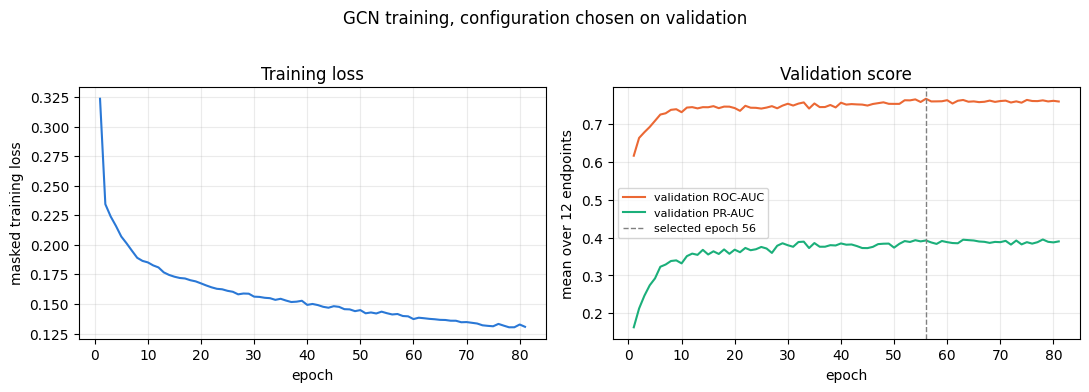

In [14]:
history = BEST["history"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(history["epoch"], history["train_loss"], color="#2a78d6")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("masked training loss"); axes[0].set_title("Training loss")
axes[1].plot(history["epoch"], history["val_roc_auc"], color="#eb6834", label="validation ROC-AUC")
axes[1].plot(history["epoch"], history["val_pr_auc"], color="#1baf7a", label="validation PR-AUC")
axes[1].axvline(BEST["best"]["epoch"], color="grey", ls="--", lw=1, label=f"selected epoch {BEST['best']['epoch']}")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("mean over 12 endpoints"); axes[1].set_title("Validation score")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.25)
fig.suptitle("GCN training, configuration chosen on validation", y=1.02)
plt.tight_layout()
(RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS_DIR / "figures" / "gnn_training_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### Seed stability, on validation only

A GCN is far more sensitive to its random initialisation than a Random Forest is. Phase 1 reports one seed, and this notebook reports one seed too, so the published numbers stay comparable — but it is worth knowing how large that uncertainty is. The chosen configuration is retrained with three seeds and scored on **validation**; the test set stays untouched.

In [15]:
seed_rows = []
for seed in SEED_CHECK:
    model, best, hist = train_gcn(BEST["params"], seed=seed)
    seed_rows.append({"seed": seed, "best_epoch": best["epoch"], "epochs_run": len(hist),
                      "val_roc_auc": best["val_roc_auc"], "val_pr_auc": best["val_pr_auc"]})
seed_table = pd.DataFrame(seed_rows)
spread = seed_table["val_roc_auc"].max() - seed_table["val_roc_auc"].min()
print(f"Validation ROC-AUC across {len(SEED_CHECK)} seeds: mean {seed_table['val_roc_auc'].mean():.4f}, "
      f"spread {spread:.4f} (min {seed_table['val_roc_auc'].min():.4f}, max {seed_table['val_roc_auc'].max():.4f})")
print("Read this as the resolution of the comparison: differences smaller than the spread mean nothing here.")
seed_table.round(4)

Validation ROC-AUC across 3 seeds: mean 0.7638, spread 0.0048 (min 0.7619, max 0.7667)
Read this as the resolution of the comparison: differences smaller than the spread mean nothing here.


,seed,best_epoch,epochs_run,val_roc_auc,val_pr_auc
0,42,56,81,0.7667,0.3924
1,43,47,72,0.7629,0.3930
2,44,42,67,0.7619,0.3838


## 7. The test set, once

Everything is now frozen: the architecture, the hyperparameters, the number of epochs and the seed. The model trained with seed 42 is scored on all three splits, and the test column is read for the first and only time.

In [16]:
model = BEST["model"]
probabilities = {s: predict(model, graphs[s]) for s in SPLITS}
params_json = json.dumps({**BEST["params"], **FIXED, "best_epoch": BEST["best"]["epoch"], "seed": SEED})

metrics = pd.concat([evaluate_endpoints(labels[s], probabilities[s]).assign(split=s) for s in SPLITS],
                    ignore_index=True)
metrics = metrics.assign(model=MODEL_NAME, feature_set=FEATURE_SET, status="trained",
                         selection_metric=SELECTION_METRIC, params=params_json)
METRIC_COLUMNS = ["model", "feature_set", "endpoint", "split", "n_observed", "n_positive", "n_negative",
                  "roc_auc", "pr_auc", "status", "selection_metric", "params"]
metrics = metrics[METRIC_COLUMNS]

summary = (metrics.groupby(["model", "feature_set", "split"], sort=False)
           .agg(mean_roc_auc=("roc_auc", "mean"), mean_pr_auc=("pr_auc", "mean"),
                endpoints_defined=("roc_auc", "count"), endpoints_total=("endpoint", "count")).reset_index())
display(summary.round(4))
metrics.query("split == 'test'")[["endpoint", "n_observed", "n_positive", "n_negative", "roc_auc", "pr_auc"]].round(3)

,model,feature_set,split,mean_roc_auc,mean_pr_auc,endpoints_defined,endpoints_total
0,gnn,graph,train,0.9331,0.6854,12,12
1,gnn,graph,val,0.7667,0.3924,12,12
2,gnn,graph,test,0.7564,0.3590,12,12


,endpoint,n_observed,n_positive,n_negative,roc_auc,pr_auc
24,NR-AR,691,14,677,0.576,0.024
25,NR-AR-LBD,598,12,586,0.800,0.301
26,NR-AhR,582,110,472,0.820,0.601
27,NR-Aromatase,490,53,437,0.834,0.535
28,NR-ER,537,72,465,0.662,0.340
29,NR-ER-LBD,631,24,607,0.690,0.181
30,NR-PPAR-gamma,559,32,527,0.810,0.311
31,SR-ARE,497,120,377,0.728,0.505
32,SR-ATAD5,645,33,612,0.779,0.258
33,SR-HSE,605,55,550,0.799,0.390


In [17]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "predictions").mkdir(parents=True, exist_ok=True)
MODEL_DIR_GRAPH = MODEL_DIR / FEATURE_SET
MODEL_DIR_GRAPH.mkdir(parents=True, exist_ok=True)

metrics.to_csv(RESULTS_DIR / "gnn_metrics.csv", index=False)
summary.to_csv(RESULTS_DIR / "gnn_summary.csv", index=False)
tuning_log.to_csv(RESULTS_DIR / "gnn_tuning_log.csv", index=False)
seed_table.to_csv(RESULTS_DIR / "gnn_seed_stability.csv", index=False)
for s in ["val", "test"]:
    pd.DataFrame({"model": MODEL_NAME, "feature_set": FEATURE_SET, "split": s,
                  "mol_id": np.repeat(splits[s]["mol_id"].to_numpy(), len(TASKS)),
                  "endpoint": np.tile(TASKS, len(splits[s])),
                  "y_true": labels[s].reshape(-1), "y_prob": probabilities[s].reshape(-1)}
                 ).to_csv(RESULTS_DIR / "predictions" / f"gnn_{FEATURE_SET}_{s}.csv", index=False)

torch.save({"state_dict": model.state_dict(), "params": {**BEST["params"], **FIXED},
            "elements": ELEMENTS, "feature_names": FEATURE_NAMES, "tasks": TASKS, "seed": SEED},
           MODEL_DIR_GRAPH / "gcn.pt")

manifest = {
    "model": MODEL_NAME, "architecture": "graph convolutional network (Kipf & Welling), multi-task",
    "feature_set": FEATURE_SET, "endpoints": TASKS,
    "graph": {"nodes": "heavy atoms", "edges": "bonds, both directions, plus self-loops",
              "adjacency": "D^-1/2 (A + I) D^-1/2", "bond_features_used_as_edge_weights": False,
              "atom_feature_blocks": ["element (vocabulary from training molecules + other)", "total degree",
                                      "formal charge", "attached hydrogens", "multiple bonds on the atom",
                                      "total valence", "aromatic flag", "in-ring flag"],
              "atom_feature_options": {"elements": ELEMENTS, "degrees": DEGREES, "charges": CHARGES,
                                       "num_hs": NUM_HS, "pi_bonds": PI_BONDS, "valences": VALENCES},
              "n_atom_features": int(N_FEATURES), "element_vocabulary": ELEMENTS,
              "element_vocabulary_z": [Chem.GetPeriodicTable().GetAtomicNumber(s) for s in ELEMENTS],
              "reproducible_in_rdkit_js": True},
    "readout": "mean and max over atoms, concatenated", "loss": "masked BCE over observed labels only",
    "chosen_params": {**BEST["params"], **FIXED}, "grid": {k: [str(x) for x in v] for k, v in GRID.items()},
    "early_stopping": {"monitor": "mean validation ROC-AUC", "patience": PATIENCE,
                       "max_epochs": MAX_EPOCHS, "best_epoch": int(BEST["best"]["epoch"]),
                       "epochs_run": int(len(BEST["history"]))},
    "n_parameters": int(count_parameters(model)),
    "multi_task": True, "one_config_for_all_endpoints": True,
    "selection_metric": SELECTION_METRIC, "seed": SEED, "refit_on_train_plus_val": False,
    "n_train_observed": {t: int(counts.loc[t, ("train", "n_observed")]) for t in TASKS},
    "n_train_positive": {t: int(counts.loc[t, ("train", "n_positive")]) for t in TASKS},
    "seed_stability_val_roc_auc": {str(r["seed"]): round(r["val_roc_auc"], 4) for r in seed_rows},
    "model_file": "gcn.pt",
    "versions": {"torch": torch.__version__, "rdkit": rdkit.__version__, "scikit-learn": sklearn.__version__},
}
(MODEL_DIR_GRAPH / "manifest.json").write_text(json.dumps(manifest, indent=2))
print("Wrote:", *sorted(str(p) for p in RESULTS_DIR.rglob("*") if p.is_file()), sep="\n  ")
print("Model:", MODEL_DIR_GRAPH / "gcn.pt", f"({(MODEL_DIR_GRAPH / 'gcn.pt').stat().st_size / 1e6:.1f} MB)")

Wrote:
  results/gnn/figures/gnn_training_curve.png
  results/gnn/gnn_metrics.csv
  results/gnn/gnn_seed_stability.csv
  results/gnn/gnn_summary.csv
  results/gnn/gnn_tuning_log.csv
  results/gnn/predictions/gnn_graph_test.csv
  results/gnn/predictions/gnn_graph_val.csv
Model: models/gnn/graph/gcn.pt (0.3 MB)


## 8. The comparison this phase exists to make

The question from the start of the project: *do learned graph representations beat fixed fingerprint-based ones, under the same split and the same protocol?*

The honest comparison is the GCN against the Phase 1 models **on Morgan fingerprints**, because both see structure alone. The morgan+descriptors rows are also shown, since those are the strongest Phase 1 models overall, but they are given extra information (12 physicochemical properties) that the GCN never receives.

This section needs `all_models_metrics.csv` from notebook 03. Without it the notebook still produces all GCN results; only this comparison is skipped.

In [18]:
comparison_file = DATA_DIR / "all_models_metrics.csv"
HAVE_PHASE1 = comparison_file.is_file()
if not HAVE_PHASE1:
    print(f"all_models_metrics.csv not found in {DATA_DIR} - skipping the comparison. "
          "Upload it (from notebook 03) to see this section.")
else:
    phase1 = pd.read_csv(comparison_file)
    # If the supplied file already carries GCN rows (from an earlier run of this notebook), drop
    # them: the comparison is between Phase 1 and the model trained above, not an older one.
    phase1 = phase1[phase1["model"] != MODEL_NAME]
    both = pd.concat([phase1[["model", "feature_set", "endpoint", "split", "roc_auc", "pr_auc"]],
                      metrics.query("split != 'train'")[["model", "feature_set", "endpoint", "split",
                                                         "roc_auc", "pr_auc"]]], ignore_index=True)
    overall = (both.groupby(["model", "feature_set", "split"], sort=False)
               .agg(mean_roc_auc=("roc_auc", "mean"), mean_pr_auc=("pr_auc", "mean")).reset_index())
    table = overall.pivot_table(index=["model", "feature_set"], columns="split",
                                values=["mean_roc_auc", "mean_pr_auc"], sort=False)
    display(table.round(4))
    structure_only = overall.query("split == 'test' and (feature_set == 'morgan' or model == 'gnn')")
    print("Structure alone, test split (the fair comparison):")
    display(structure_only[["model", "feature_set", "mean_roc_auc", "mean_pr_auc"]]
            .sort_values("mean_roc_auc", ascending=False).round(4).to_string(index=False))

mean_roc_auc         mean_pr_auc        
split                                           val    test         val    test
model               feature_set                                                
logistic_regression morgan                   0.7239  0.7016      0.3230  0.2774
                    descriptors              0.7232  0.6662      0.2216  0.2188
                    morgan+descriptors       0.7486  0.7386      0.2970  0.2688
random_forest       morgan                   0.7497  0.7164      0.3825  0.3173
                    descriptors              0.7433  0.7361      0.3325  0.3010
                    morgan+descriptors       0.7850  0.7635      0.4069  0.3702
xgboost             morgan                   0.7366  0.7125      0.3495  0.2815
                    descriptors              0.7490  0.7104      0.3368  0.2686
                    morgan+descriptors       0.7739  0.7552      0.3906  0.3541
gnn                 graph                    0.7667  0.7564      0.3924  0.3590

Structure alone, test split (the fair comparison):


'              model feature_set  mean_roc_auc  mean_pr_auc\n                gnn       graph        0.7564       0.3590\n      random_forest      morgan        0.7164       0.3173\n            xgboost      morgan        0.7125       0.2815\nlogistic_regression      morgan        0.7016       0.2774'

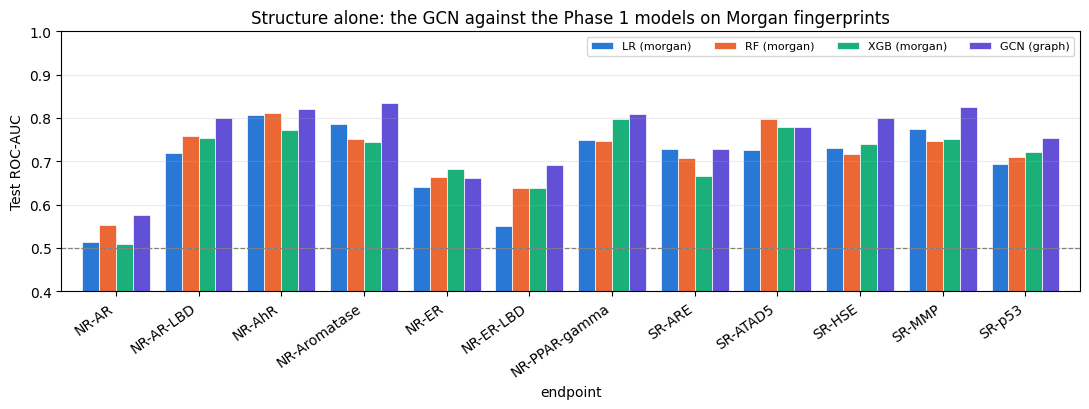

Endpoints where each model has the highest test ROC-AUC (structure-only setting):
{'GCN (graph)': 9, 'XGB (morgan)': 1, 'LR (morgan)': 1, 'RF (morgan)': 1}

GCN mean 0.7564 vs best fingerprint model 0.7164 (RF (morgan))


In [19]:
if HAVE_PHASE1:
    wide = (both.query("split == 'test' and (feature_set == 'morgan' or model == 'gnn')")
            .pivot(index="endpoint", columns="model", values="roc_auc").loc[TASKS])
    wide = wide[[c for c in ["logistic_regression", "random_forest", "xgboost", "gnn"] if c in wide.columns]]
    colours = {"logistic_regression": "#2a78d6", "random_forest": "#eb6834",
               "xgboost": "#1baf7a", "gnn": "#6250d6"}
    labels_short = {"logistic_regression": "LR (morgan)", "random_forest": "RF (morgan)",
                    "xgboost": "XGB (morgan)", "gnn": "GCN (graph)"}
    ax = wide.rename(columns=labels_short).plot.bar(
        figsize=(11, 4.2), width=0.82, color=[colours[c] for c in wide.columns], edgecolor="white", linewidth=0.5)
    ax.axhline(0.5, color="grey", lw=0.9, ls="--")
    ax.set_ylim(0.4, 1.0)
    ax.set_ylabel("Test ROC-AUC")
    ax.set_title("Structure alone: the GCN against the Phase 1 models on Morgan fingerprints")
    ax.legend(fontsize=8, ncol=4)
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "figures" / "gnn_vs_aml_roc_auc.png", dpi=150, bbox_inches="tight")
    plt.show()

    wins = wide.idxmax(axis=1).value_counts()
    print("Endpoints where each model has the highest test ROC-AUC (structure-only setting):")
    print({labels_short[k]: int(v) for k, v in wins.items()})
    print(f"\nGCN mean {wide['gnn'].mean():.4f} vs best fingerprint model "
          f"{wide.drop(columns='gnn').mean().max():.4f} "
          f"({labels_short[wide.drop(columns='gnn').mean().idxmax()]})")

## 9. Predicting new molecules

The saved model needs the same atom features in the same order, so the element vocabulary is stored alongside the weights. A SMILES should be standardised the way Member 1 standardised the training data (largest fragment, canonical form) before it is predicted.

In [20]:
def load_gcn(folder: Path = None):
    """Reload the saved GCN. Only load checkpoints your own team produced."""
    folder = folder or MODEL_DIR_GRAPH
    payload = torch.load(folder / "gcn.pt", weights_only=False)
    reloaded = GCN(len(payload["feature_names"]), payload["params"]["hidden"], payload["params"]["layers"],
                   len(payload["tasks"]), payload["params"]["dropout"])
    reloaded.load_state_dict(payload["state_dict"])
    reloaded.eval()
    return reloaded, payload

def largest_fragment_smiles(smiles: str) -> str:
    """Member 1's rule: keep the fragment with the most heavy atoms, then write canonical SMILES."""
    mol = parse_smiles(smiles)
    fragments = Chem.GetMolFrags(mol, asMols=True, sanitizeFrags=True)
    best = mol if len(fragments) == 1 else max(fragments, key=lambda m: m.GetNumHeavyAtoms())
    return Chem.MolToSmiles(best, canonical=True)

def predict_smiles(smiles_list: Sequence[str], names: Sequence[str] = None) -> pd.DataFrame:
    reloaded, payload = load_gcn()
    rows, used = [], []
    for i, smiles in enumerate(smiles_list):
        name = names[i] if names else str(i)
        try:
            canonical = largest_fragment_smiles(smiles)
            used.append(to_graph(canonical, payload["elements"]))
            rows.append({"name": name, "canonical_smiles": canonical})
        except ValueError as error:
            print(f"skipped {name}: {error}")
    if not rows:
        return pd.DataFrame()
    probabilities = predict(reloaded, used)
    out = pd.DataFrame(rows)
    for j, task in enumerate(payload["tasks"]):
        out[task] = probabilities[:, j]
    return out

demo = predict_smiles(["CC(=O)Nc1ccc(O)cc1", "c1ccc(cc1)Oc1ccc(Cl)cc1Cl", "CC(=O)[O-].[Na+]", "not_a_smiles"],
                      ["paracetamol", "a chlorinated diphenyl ether", "sodium acetate", "bad input"])
demo.round(3)

skipped bad input: RDKit could not read the SMILES 'not_a_smiles'


,name,canonical_smiles,NR-AR,NR-AR-LBD,NR-AhR,NR-Aromatase,NR-ER,NR-ER-LBD,NR-PPAR-gamma,SR-ARE,SR-ATAD5,SR-HSE,SR-MMP,SR-p53
0,paracetamol,CC(=O)Nc1ccc(O)cc1,0.020,0.006,0.115,0.003,0.134,0.026,0.002,0.089,0.015,0.022,0.049,0.022
1,a chlorinated diphenyl ether,Clc1ccc(Oc2ccccc2)c(Cl)c1,0.017,0.008,0.090,0.027,0.124,0.033,0.049,0.133,0.007,0.078,0.537,0.040
2,sodium acetate,CC(=O)[O-],0.001,0.000,0.000,0.000,0.030,0.000,0.000,0.006,0.000,0.000,0.000,0.000


## 10. Viva notes: what the GCN does, and what it does not

**One layer.** Each atom's vector is multiplied by a learned weight matrix, then replaced by the normalised average of itself and its bonded neighbours: $H^{(l+1)} = \sigma(\hat{A} H^{(l)} W^{(l)})$. The self-loop in $\hat{A} = \tilde{D}^{-1/2}(A+I)\tilde{D}^{-1/2}$ keeps the atom's own information; the $\tilde{D}^{-1/2}$ factors stop high-degree atoms dominating.

**Depth = radius.** After *L* layers an atom knows about everything within *L* bonds. This is the same notion of locality as a Morgan fingerprint of radius *L*. The difference is what happens to that neighbourhood: the fingerprint hashes it into a bit (and two different neighbourhoods can collide in the same bit), while the GCN maps it into a continuous vector it learns for the task. That is the whole argument for graph models — and why 2 or 3 layers, not 10, is the sensible range for drug-sized molecules.

**Why not more layers.** With too many layers every atom's vector converges towards the same value (over-smoothing), and the molecule's distinguishing detail is averaged away. The grid searched 2 and 3 for this reason.

**Pooling.** Predictions are per molecule, so atom vectors are reduced by mean (the average character of the molecule) and maximum (the strongest single atom signal, which is what matters when one reactive group drives toxicity). Both ignore atom order, so the prediction cannot depend on how the SMILES happened to be written.

**Multi-task learning.** One network predicts all 12 assays and shares every graph-convolution layer between them. The 12 assays are biologically related, and the endpoints with few actives can borrow structure learned from the endpoints with many. This is a genuine advantage over Phase 1, where each endpoint has an independent model that learns from its own labels alone — and it is part of why a comparison of "GCN vs Random Forest" is really a comparison of two whole pipelines, not of two layers of maths.

**Masking is the heart of the loss.** 17% of the label matrix was never measured. Those entries are multiplied by zero, so they contribute neither loss nor gradient. Filling them with 0 instead would add roughly 16,000 fabricated "inactive" training examples per split and inflate every score, and the gradient check in section 5 exists to prove this notebook does not do it.

**What this notebook cannot claim.** Bond types are ignored *as edge weights*, so a double bond and a single bond pass the same message; a message-passing network (MPNN) or GIN with edge features would use them directly, and the atom-level multiple-bond and valence blocks are only a partial substitute. The feature set is also constrained by deployment: it uses only what RDKit can expose in a browser, which cost 0.0015 validation ROC-AUC against a version using hybridisation — a deliberate trade of a little accuracy for a model whose predictions can be proven identical wherever they run. The split is one scaffold split with one seed, and the seed-stability check in section 6 shows how much of any small gap is noise. The GCN was tuned once for all 12 endpoints while Phase 1 tuned each endpoint separately. And every number here is in-vitro assay activity, not human toxicity.

## 11. Sanity checks (all should print OK)

In [21]:
# 1. Rows, shapes and alignment
for s in SPLITS:
    assert probabilities[s].shape == (len(splits[s]), len(TASKS))
    assert np.isfinite(probabilities[s]).all() and (probabilities[s] >= 0).all() and (probabilities[s] <= 1).all()
saved_test = pd.read_csv(RESULTS_DIR / "predictions" / f"gnn_{FEATURE_SET}_test.csv", dtype={"mol_id": str})
assert len(saved_test) == len(splits["test"]) * len(TASKS)
assert saved_test["mol_id"].iloc[::len(TASKS)].tolist() == splits["test"]["mol_id"].tolist()
print("OK 1: probabilities are valid and every row follows Member 1's mol_id order")

# 2. Missing labels stayed missing, in training and in the saved files
assert int(saved_test["y_true"].isna().sum()) == int(counts["test"]["n_missing"].sum())
for row in metrics.itertuples():
    observed = int(counts.loc[row.endpoint, (row.split, "n_observed")])
    assert row.n_observed == observed, (row.endpoint, row.split, row.n_observed, observed)
    assert row.n_positive == int(counts.loc[row.endpoint, (row.split, "n_positive")])
print("OK 2: every metric used exactly the observed labels of its split; NaN labels kept as NaN")

# 3. The tuning log contains validation scores only, so the test set could not have influenced any choice
assert any(c.startswith("val_") for c in tuning_log.columns)
assert not any("test" in c for c in tuning_log.columns)
assert len(tuning_log) == len(configurations) and int(tuning_log["selected"].sum()) == 1
print(f"OK 3: {len(tuning_log)} configurations logged with validation scores only, exactly one selected")

# 4. The saved model reloads and reproduces the test probabilities
reloaded, payload = load_gcn()
assert payload["elements"] == ELEMENTS and payload["tasks"] == TASKS
difference = np.abs(predict(reloaded, graphs["test"]) - probabilities["test"]).max()
assert difference < 1e-6, difference
print(f"OK 4: the saved model reloads and reproduces its test probabilities (max difference {difference:.1e})")

# 5. The reported test score is the one from the selected configuration, not the best of the grid
assert bool(tuning_log.loc[chosen_index, "selected"])
assert abs(tuning_log.loc[chosen_index, "val_roc_auc"]
           - metrics.query("split == 'val'")["roc_auc"].mean()) < 1e-9
print("OK 5: the published validation score belongs to the configuration that was selected")

# 6. No molecule leaked between splits (re-checked after graph building)
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert not set(splits[a]["smiles"]) & set(splits[b]["smiles"])
print("OK 6: no structure is shared between train, validation and test")
print("\nAll sanity checks passed.")

OK 1: probabilities are valid and every row follows Member 1's mol_id order
OK 2: every metric used exactly the observed labels of its split; NaN labels kept as NaN
OK 3: 16 configurations logged with validation scores only, exactly one selected


OK 4: the saved model reloads and reproduces its test probabilities (max difference 0.0e+00)
OK 5: the published validation score belongs to the configuration that was selected
OK 6: no structure is shared between train, validation and test

All sanity checks passed.


## 12. Save and download

Output files, in the same formats the other notebooks use, so the results drop straight into the project's `results/` folder:

* `results/gnn/gnn_metrics.csv` — columns `model, feature_set, endpoint, split, n_observed, n_positive, n_negative, roc_auc, pr_auc, status, selection_metric, params`. One row per endpoint × split. `feature_set` is `graph`.
* `results/gnn/gnn_summary.csv` — mean ROC-AUC and PR-AUC per split.
* `results/gnn/gnn_tuning_log.csv` — every configuration tried, with **validation** scores only.
* `results/gnn/gnn_seed_stability.csv` — the chosen configuration retrained with three seeds, validation only.
* `results/gnn/predictions/gnn_graph_{val,test}.csv` — columns `model, feature_set, split, mol_id, endpoint, y_true, y_prob`, with `y_true` empty where the label is missing.
* `results/gnn/figures/` — the training curve and, if notebook 03's metrics were supplied, the comparison chart.
* `models/gnn/graph/gcn.pt` and `manifest.json` — the weights, the atom-feature vocabulary needed to reuse them, and every setting.

In [22]:
for folder in MODEL_DIR.glob("*"):
    target = RESULTS_DIR / "model_manifests" / folder.name
    target.mkdir(parents=True, exist_ok=True)
    shutil.copy(folder / "manifest.json", target / "manifest.json")

archive = shutil.make_archive("member4_gnn_outputs", "zip", ".", RESULTS_DIR.parent.name)
print(f"{archive}: {os.path.getsize(archive) / 1e6:.2f} MB")
print(f"{MODEL_DIR_GRAPH / 'gcn.pt'}: {(MODEL_DIR_GRAPH / 'gcn.pt').stat().st_size / 1e6:.2f} MB "
      "(small enough to commit, unlike the Phase 1 forests)")

DOWNLOAD = False
if IN_COLAB and DOWNLOAD:
    colab_files.download(archive)

/private/tmp/claude-501/-Users-manpreetsingh--claude-spares-spare-jv5amu/83853ebc-daaf-4957-bfbf-47685046130f/scratchpad/run04/member4_gnn_outputs.zip: 0.32 MB
models/gnn/graph/gcn.pt: 0.33 MB (small enough to commit, unlike the Phase 1 forests)
